In [27]:
import pandas as pd

df = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")

In [28]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [29]:
df.head(10)
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [30]:
#1. Fix the date
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [31]:
# 2. Drop rows with no customer
df = df.dropna(subset=["Customer ID"])


#dropna removes rows with blanks. subset=["Customer ID"] means “only look at this column.” No customer ID means we can’t tell who bought, so RFM can’t use the row. This removes ~243k rows.

In [32]:
#3. Make Customer ID a whole number
df["Customer ID"] = df["Customer ID"].astype(int)

#It was 13085.0 (decimal) because blanks forced the column to float. Now that blanks are gone, we convert to 13085

In [33]:
#4. Remove cancellations
df = df[~df["Invoice"].astype(str).str.startswith("C")]
#.astype(str) makes sure Invoice is text
#.str.startswith("C") is True for cancelled orders (like C489449)
#~ flips it, so we keep rows that do not start with “C”


In [34]:
#Remove bad quantity and price
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
#Keep only rows where both are above zero. This kills the negative returns and the weird -53,594 price. & means “and”, and each condition needs its own brackets.

In [35]:
df = df.drop_duplicates()

In [36]:
df["Revenue"] = df["Quantity"] * df["Price"]
#7. Create Revenue

In [37]:
print(df.shape)
df.describe()

(779425, 9)


,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,779425.000000,779425,779425.000000,779425.000000,779425.000000
mean,13.489370,2011-01-03 01:44:42.593476,3.218488,15320.360461,22.291823
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000,4.950000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000,12.480000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000,168469.600000
std,145.855814,NaN,29.676140,1695.692775,227.427075


RFM table

In [38]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

print(rfm.shape)
rfm.head()
rfm.describe()

(5878, 3)


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


In [39]:
print("Last date in data:", df["InvoiceDate"].max())
print("Snapshot date:   ", snapshot)

Last date in data: 2011-12-09 12:50:00
Snapshot date:    2011-12-10 12:50:00


What pd.qcut does

qcut = “quantile cut.” It sorts all customers and splits them into 5 equal-sized groups.

With 5,878 customers, each group gets about 1,176 people.

For Monetary:

Bottom 20% of spenders → score 1
Next 20% → 2
...
Top 20% of spenders → score 5

In [40]:
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5,4,3,2,1])
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5])
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1,2,3,4,5])
rfm.head() 

,Recency,Frequency,Monetary,R,F,M
Customer ID,,,,,,
12346,326,12,77556.46,2,5,5
12347,2,8,4921.53,5,4,5
12348,75,5,2019.40,3,4,4
12349,19,4,4428.69,5,3,5
12350,310,1,334.40,2,1,2


Turn scores into segments

In [41]:
def segment(r):
    r_, f_ = int(r["R"]), int(r["F"])
    if r_ >= 4 and f_ >= 4: return "Champions"
    if r_ >= 3 and f_ >= 3: return "Loyal"
    if r_ >= 4 and f_ <= 2: return "New / Promising"
    if r_ <= 2 and f_ >= 3: return "At Risk"
    if r_ <= 2 and f_ <= 2: return "Lost"
    return "Needs Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)

summary = rfm.groupby("Segment").agg(
    Customers=("Monetary", "count"),
    Revenue=("Monetary", "sum"),
    Avg_Spend=("Monetary", "mean"),
)
summary["Revenue_%"] = (summary["Revenue"] / summary["Revenue"].sum() * 100).round(1)
summary["Customers_%"] = (summary["Customers"] / summary["Customers"].sum() * 100).round(1)
summary.sort_values("Revenue", ascending=False)

,Customers,Revenue,Avg_Spend,Revenue_%,Customers_%
Segment,,,,,
Champions,1482,1.202433e+07,8113.583094,69.2,25.2
Loyal,1221,2.510046e+06,2055.730013,14.4,20.8
At Risk,824,1.589384e+06,1928.864456,9.1,14.0
Lost,1523,6.544267e+05,429.695799,3.8,25.9
New / Promising,443,3.922670e+05,885.478600,2.3,7.5
Needs Attention,385,2.043497e+05,530.778553,1.2,6.5


In [42]:
import matplotlib.pyplot as plt

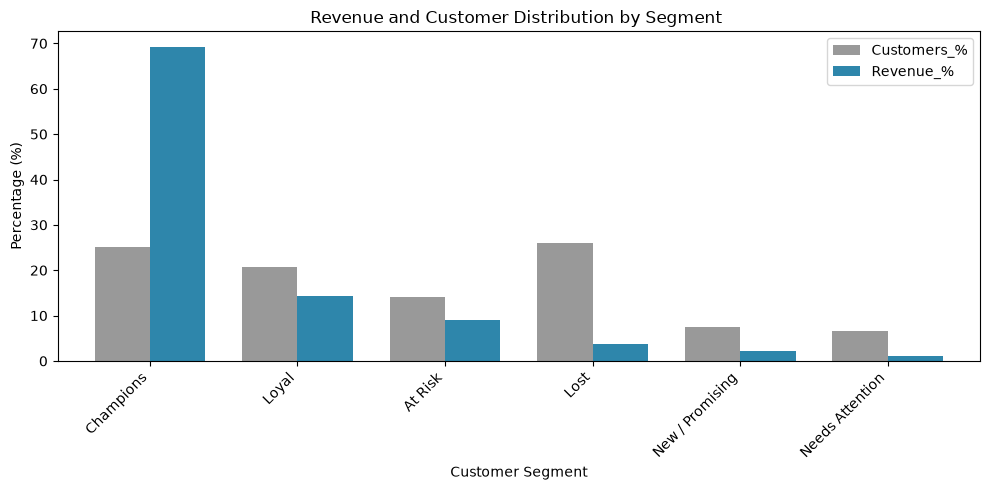

In [43]:
summary = summary.sort_values("Revenue", ascending=False)
colors = ["#2E86AB", "#59A5D8", "#F6AE2D", "#F26419", "#86BBD8", "#999999"]


#chart 1: Revenue by segment
ax = summary[["Customers_%", "Revenue_%"]].plot(
    kind="bar", figsize=(10, 5), color=["#999999", "#2E86AB"], width=0.75
)
ax.set_title('Revenue and Customer Distribution by Segment ')
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('Customer Segment')   
plt.xticks(rotation=45 , ha='right')
plt.tight_layout()
plt.show()



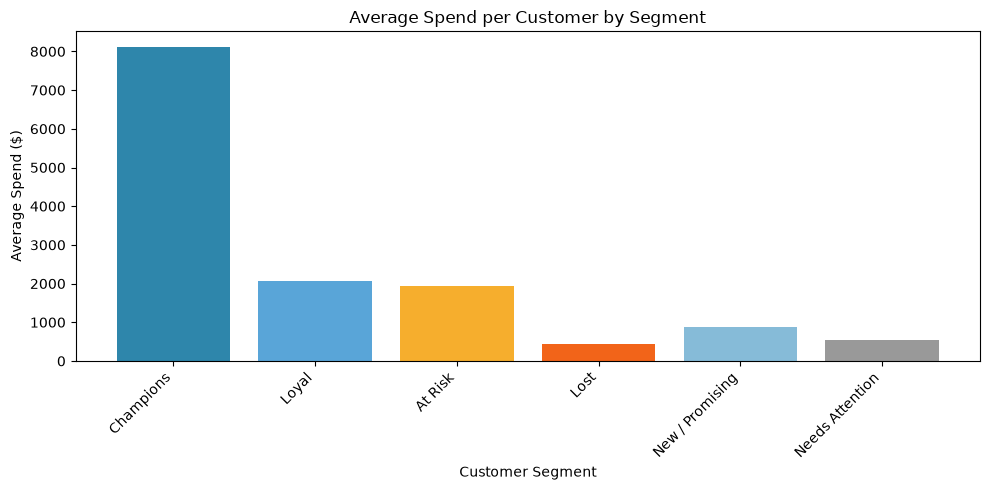

In [44]:
# Chart 2: Average spend per customer

plt.figure(figsize=(10, 5))
plt.bar(summary.index, summary["Avg_Spend"], color=colors)
plt.title('Average Spend per Customer by Segment')
plt.ylabel('Average Spend ($)')
plt.xlabel('Customer Segment')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

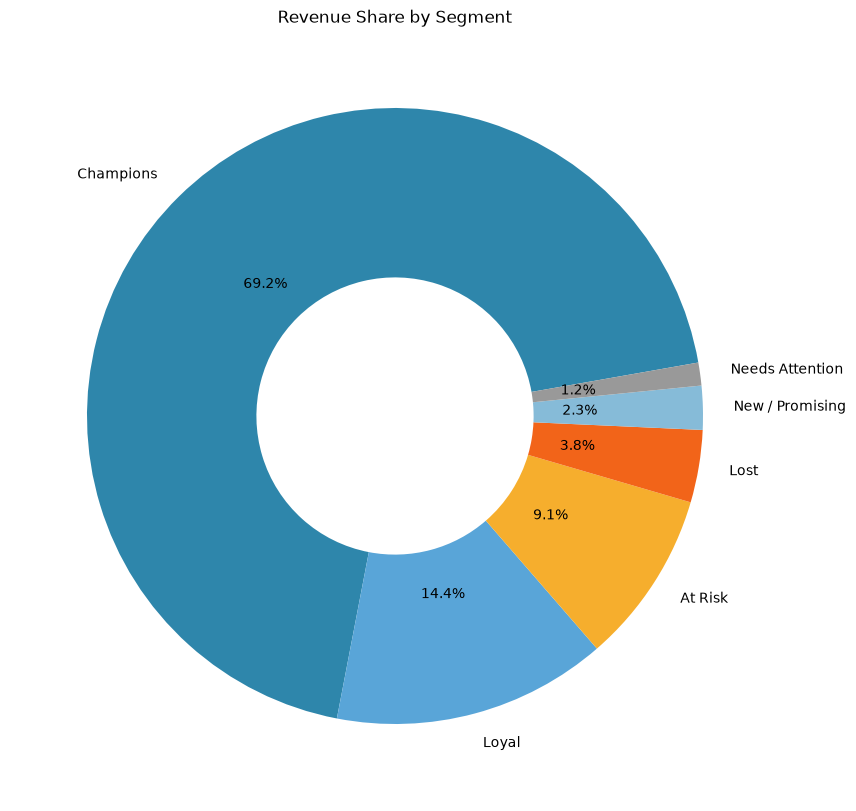

In [45]:
# Chart 3: Revenue share donut
plt.figure(figsize=(10, 10))
plt.pie(summary["Revenue_%"], labels=summary.index, autopct="%1.1f%%",
        colors=colors, startangle=10, wedgeprops={"width": 0.55})
plt.title("Revenue Share by Segment")
plt.show()

In [1]:
# Machine learning (K-Means)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
X_scaled = StandardScaler().fit_transform(X)

NameError: name 'np' is not defined